In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylab as pl

In [6]:
df = pd.read_csv('data/FuelConsumption.csv')

In [7]:
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [9]:
df['ENGINESIZE'].head()

0    2.0
1    2.4
2    1.5
3    3.5
4    3.5
Name: ENGINESIZE, dtype: float64

In [13]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [17]:
cdf = df[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
cdf.head(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244
5,3.5,6,10.0,230
6,3.5,6,10.1,232
7,3.7,6,11.1,255
8,3.7,6,11.6,267


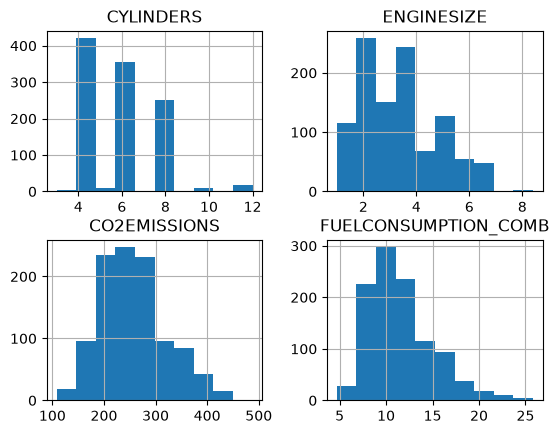

In [19]:
viz = cdf[['CYLINDERS','ENGINESIZE','CO2EMISSIONS','FUELCONSUMPTION_COMB']]
viz.hist()
plt.show()

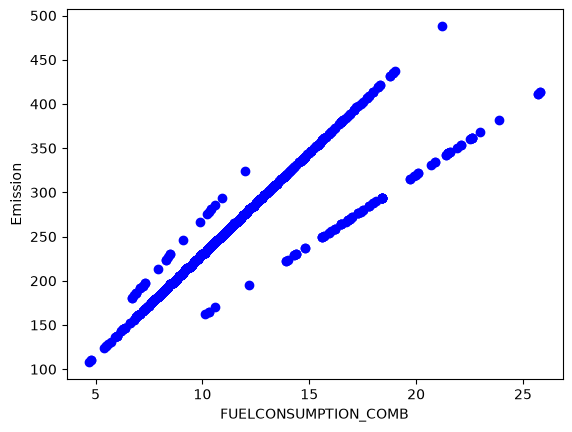

In [27]:
plt.scatter(cdf.FUELCONSUMPTION_COMB,cdf.CO2EMISSIONS,color='blue')

plt.xlabel('FUELCONSUMPTION_COMB')
plt.ylabel('Emission')
plt.show()

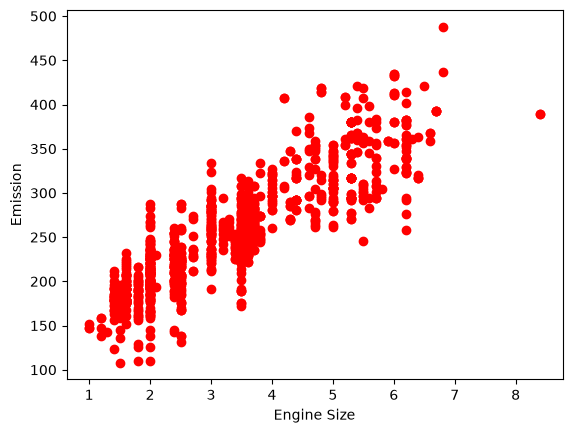

In [24]:
plt.scatter(cdf.ENGINESIZE,cdf.CO2EMISSIONS,color='red')
plt.xlabel('Engine Size')
plt.ylabel('Emission')
plt.show()

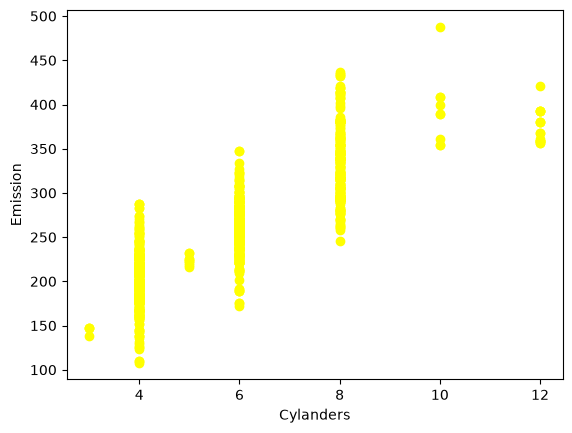

In [29]:
plt.scatter(cdf.CYLINDERS,cdf.CO2EMISSIONS,color='yellow')
plt.xlabel('Cylanders')
plt.ylabel('Emission')
plt.show()


In [41]:
msk = np.random.rand(len(df)) < 0.8
trian = cdf[msk]
test = cdf[~msk]

In [42]:
len(trian)

845

In [43]:
len(test)

222

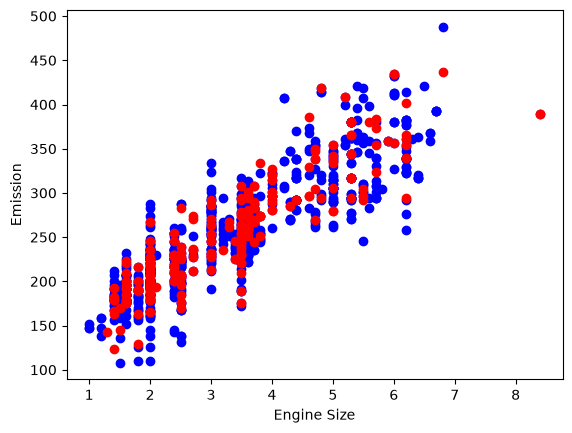

In [44]:
plt.scatter(trian.ENGINESIZE,trian.CO2EMISSIONS,color='blue')
plt.scatter(test.ENGINESIZE,test.CO2EMISSIONS,color='red')

plt.xlabel('Engine Size')
plt.ylabel('Emission')
plt.show()

In [47]:
from sklearn import linear_model
reg = linear_model.LinearRegression()
train_x = np.asanyarray(trian[['ENGINESIZE']])
train_y = np.asanyarray(trian[['CO2EMISSIONS']])
reg.fit(train_x,train_y)
print('Coefficients',reg.coef_)
print('Intercept',reg.intercept_)


Coefficients [[38.61971343]]
Intercept [126.71088562]


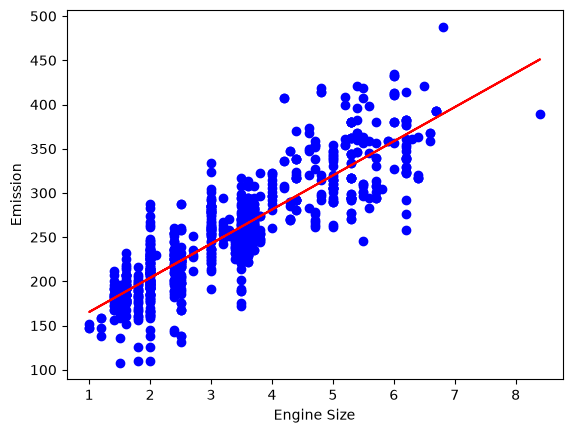

In [53]:
plt.scatter(trian.ENGINESIZE,trian.CO2EMISSIONS,color='blue')

plt.plot(train_x,reg.coef_[0][0]*train_x + reg.intercept_[0],'-r')
plt.xlabel('Engine Size')
plt.ylabel('Emission')
plt.show()

In [55]:
from sklearn.metrics import r2_score
test_x = np.asanyarray(test[['ENGINESIZE']])
test_y = np.asanyarray(test[['CO2EMISSIONS']])
test_y_ = reg.predict(test_x)

print('Mean absolute error: %.2f' % np.mean(np.absolute(test_y_ - test_y)))
print('Residual sum of squares (MSE): %.2f' % np.mean((test_y_ - test_y) ** 2 ))
print('R2-score: %.2f' %r2_score(test_y,test_y_))

Mean absolute error: 21.88
Residual sum of squares (MSE): 831.18
R2-score: 0.80


In [59]:
reg.predict([[8]])

array([[435.66859304]])